In [26]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
# import 'Modelling.csv' file from the Data directory
df = pd.read_csv('../Data/Modelling.csv')
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour_of_day,day,dest_prev_txn_count,dest_prev_amount_sum,dest_is_first_txn,dest_txn_count_24h
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,1,0,0,0.0,1,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1,0,0,0.0,1,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,1,0,0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,1,0,0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,1,0,0,0.0,1,0


In [28]:
# Filter the dataframe to only include rows where the 'Type' is 'TRANSFER' or 'CASH_OUT'
df = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])]

# Drop the following columns from the dataframe: 'nameOrig', 'nameDest', 'isFlaggedFraud', oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'day'
df = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'day'])  

df.head()



,step,type,amount,isFraud,hour_of_day,dest_prev_txn_count,dest_prev_amount_sum,dest_is_first_txn,dest_txn_count_24h
2,1,TRANSFER,181.00,1,1,0,0.0,1,0
3,1,CASH_OUT,181.00,1,1,0,0.0,1,0
15,1,CASH_OUT,229133.94,0,1,0,0.0,1,0
19,1,TRANSFER,215310.30,0,1,0,0.0,1,0
24,1,TRANSFER,311685.89,0,1,0,0.0,1,0


In [29]:
# sort the dataframe by step and hour_of_day in ascending order
df = df.sort_values(by=['step', 'hour_of_day'], ascending=[True, True])

In [30]:
# percentage of fraudulent transactions in the dataset
fraud_percentage = df['isFraud'].mean() * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage:.2f}%")

# percentage of non-fraudulent transactions in the dataset
non_fraud_percentage = 100 - fraud_percentage
print(f"Percentage of non-fraudulent transactions: {non_fraud_percentage:.2f}%")

Percentage of fraudulent transactions: 0.30%
Percentage of non-fraudulent transactions: 99.70%


# Data Preprocessing / One Hot encoding

In [31]:
d = df.copy()

# Extra features
d["is_night"]         = d["hour_of_day"].between(0, 6).astype(int)
d["amount_1M_to_10M"] = d["amount"].between(1e6, 1e7).astype(int)
d["amount_is_10M"]    = (d["amount"] == 1e7).astype(int)

# Time-based split (requires the step column)
cut = d["step"].quantile(0.8)
train, test = d[d.step <= cut], d[d.step > cut]

log_cols   = ["amount", "dest_prev_amount_sum", "dest_prev_txn_count", "dest_txn_count_24h"]
cat_cols   = ["type"]
flag_cols  = ["is_night", "dest_is_first_txn", "amount_1M_to_10M", "amount_is_10M"]
features   = log_cols + cat_cols + flag_cols

pre = ColumnTransformer([
    ("log_scale", Pipeline([("log", FunctionTransformer(np.log1p)),
                            ("scale", StandardScaler())]), log_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("flags", "passthrough", flag_cols),
])

In [32]:

lr_model = Pipeline(steps=[
    ("preprocessor", pre),
    ("classifier", LogisticRegression(
        max_iter = 1000,
        class_weight="balanced",
        solver="liblinear",
        penalty="l1",
        C=0.001
    ))
])

lr_model.fit(train[features], train["isFraud"])

lr_model

/Users/muneebhassan/Desktop/VaultGuard/vaultguard/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/muneebhassan/Desktop/VaultGuard/vaultguard/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['amount','dest_prev_amount_sum','dest_prev_txn_count',..., 'dest_is_first_txn','amount_1M_to_10M','amount_is_10M']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_scale', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

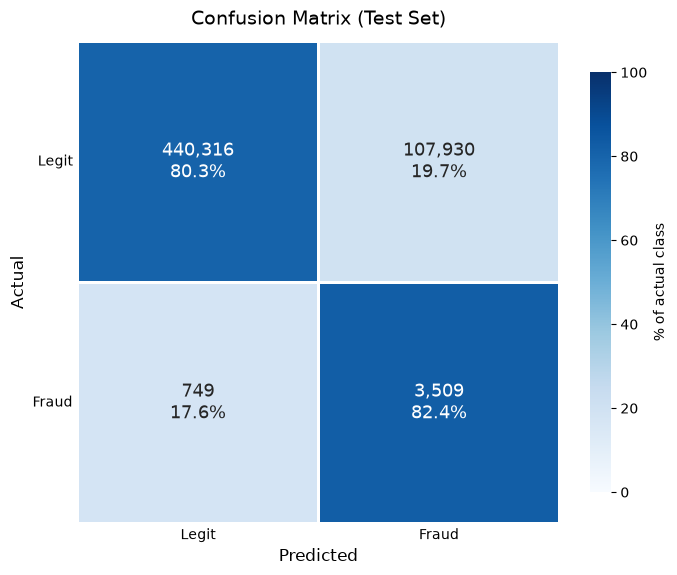

In [33]:
predictions = lr_model.predict(test[features])
# confusion matrix for predictions against test["isFraud"]
cm = confusion_matrix(test["isFraud"], predictions)
cm

# Colour each cell by its share of the actual class (row %), since raw counts are dominated by the legit class
cm_row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
cell_labels = np.array([[f"{count:,}\n{pct:.1f}%" for count, pct in zip(count_row, pct_row)]
                        for count_row, pct_row in zip(cm, cm_row_pct)])
class_names = ["Legit", "Fraud"]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_row_pct, annot=cell_labels, fmt="", cmap="Blues", vmin=0, vmax=100,
            linewidths=2, linecolor="white", square=True,
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"fontsize": 13}, cbar_kws={"label": "% of actual class", "shrink": 0.8}, ax=ax)

ax.set_title("Confusion Matrix (Test Set)", fontsize=14, pad=12)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.tick_params(length=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [34]:
# store the logistic regression model in a joblib file in the Models directory
joblib.dump(lr_model, '../models/logistic_regression_model.joblib')

['../models/logistic_regression_model.joblib']